In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [7]:

from pathlib import Path
import pandas as pd

DATA_FILE = Path(r"C:\Users\Anuja\Downloads\archive (1)\Social_media_impact_on_life.csv")

df = pd.read_csv(DATA_FILE)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (4500, 16)


,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial


In [8]:

# Check dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Fill missing numerical values with the median
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill missing text values with the most common value
text_cols = df.select_dtypes(include=["object", "category"]).columns

for col in text_cols:
    if df[col].isnull().any():
        mode_values = df[col].mode()
        if not mode_values.empty:
            df[col] = df[col].fillna(mode_values.iloc[0])

print("\nData cleaning completed!")
print("Remaining missing values:", df.isnull().sum().sum())

display(df.head())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Student_ID                   4500 non-null   object 
 1   Age                          4500 non-null   int64  
 2   Gender                       4500 non-null   object 
 3   Academic_Level               4500 non-null   object 
 4   Primary_Platform             4500 non-null   object 
 5   Daily_Usage_Hours            4500 non-null   float64
 6   Weekend_Extra_Hours          4500 non-null   float64
 7   Device_Type                  4500 non-null   object 
 8   Sleep_Duration_Hours         4500 non-null   float64
 9   Sleep_Quality_Score          4500 non-null   int64  
 10  Late_Night_Usage             4500 non-null   bool   
 11  Social_Comparison_Frequency  4500 non-null   object 
 12  Perceived_Stress_Score       4454 non-null   float64
 1

,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial


In [9]:

print("SOCIAL MEDIA IMPACT ANALYSIS")
print("-" * 35)

columns = [
    "Daily_Usage_Hours",
    "Sleep_Duration_Hours",
    "Perceived_Stress_Score",
    "Mental_Health_Index",
    "Academic_Performance_GPA"
]

for col in columns:
    if col in df.columns:
        values = df[col].dropna().to_numpy()

        if len(values) > 0:
            print("\n", col)
            print("Average:", round(np.mean(values), 2))
            print("Maximum:", np.max(values))
            print("Minimum:", np.min(values))
            print("Standard deviation:", round(np.std(values), 2))


SOCIAL MEDIA IMPACT ANALYSIS
-----------------------------------

 Daily_Usage_Hours
Average: 5.3
Maximum: 14.0
Minimum: 0.9
Standard deviation: 2.6

 Sleep_Duration_Hours
Average: 6.7
Maximum: 10.5
Minimum: 3.0
Standard deviation: 1.19

 Perceived_Stress_Score
Average: 13.51
Maximum: 40.0
Minimum: 0.0
Standard deviation: 7.04

 Mental_Health_Index
Average: 79.87
Maximum: 98
Minimum: 32
Standard deviation: 12.87

 Academic_Performance_GPA
Average: 3.43
Maximum: 4.0
Minimum: 1.9
Standard deviation: 0.39


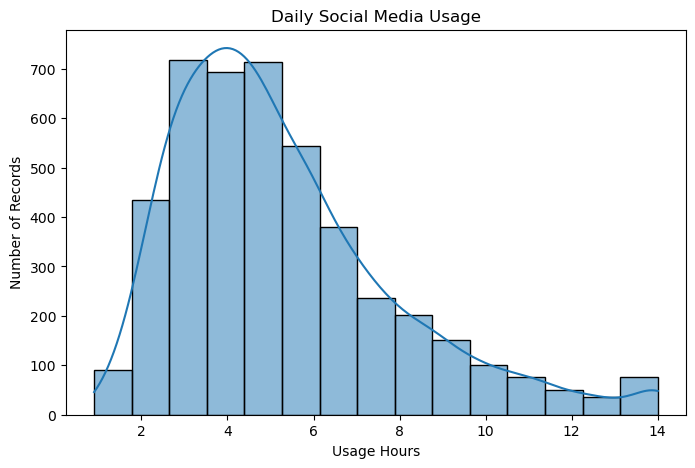

In [10]:

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Daily_Usage_Hours",
    bins=15,
    kde=True
)

plt.title("Daily Social Media Usage")
plt.xlabel("Usage Hours")
plt.ylabel("Number of Records")

plt.show()


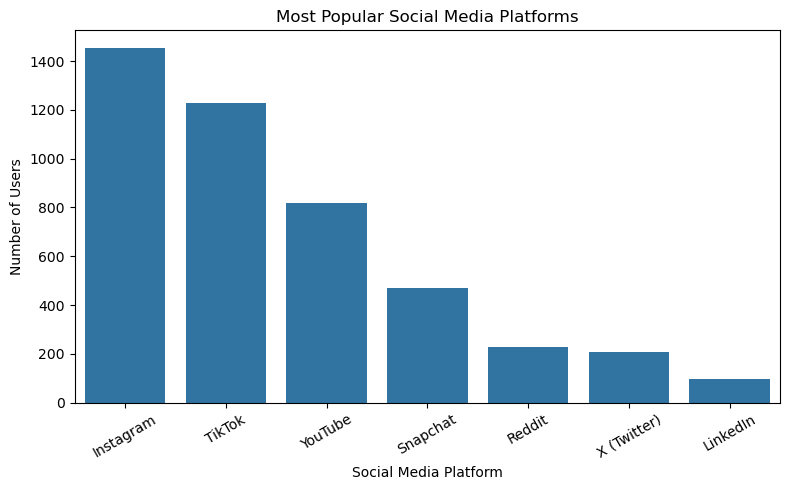

In [11]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Primary_Platform",
    order=df["Primary_Platform"].value_counts().index
)

plt.title("Most Popular Social Media Platforms")
plt.xlabel("Social Media Platform")
plt.ylabel("Number of Users")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


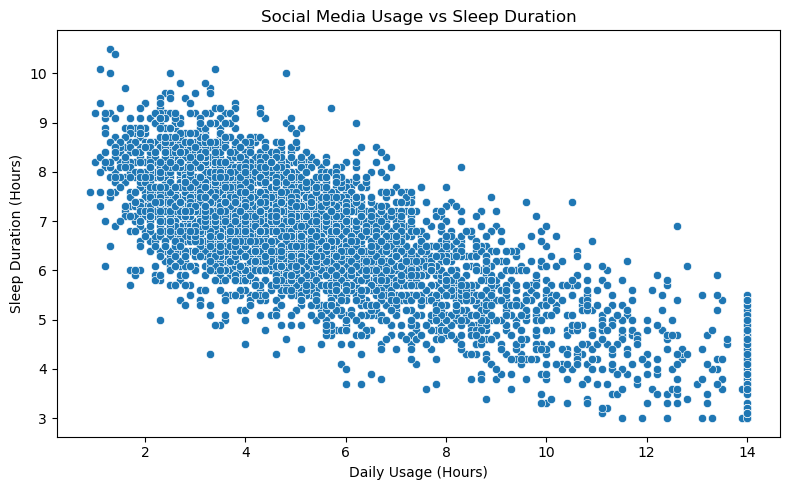

In [12]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Daily_Usage_Hours",
    y="Sleep_Duration_Hours"
)

plt.title("Social Media Usage vs Sleep Duration")
plt.xlabel("Daily Usage (Hours)")
plt.ylabel("Sleep Duration (Hours)")

plt.tight_layout()
plt.show()


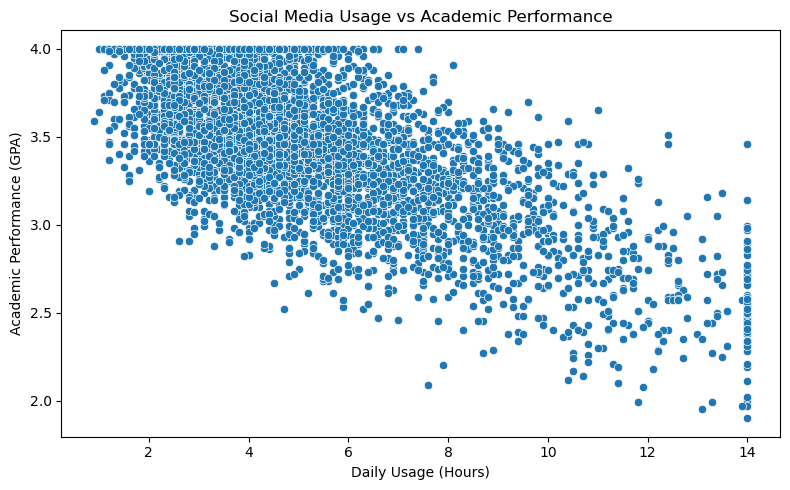

In [13]:

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Daily_Usage_Hours",
    y="Academic_Performance_GPA"
)

plt.title("Social Media Usage vs Academic Performance")
plt.xlabel("Daily Usage (Hours)")
plt.ylabel("Academic Performance (GPA)")

plt.tight_layout()
plt.show()


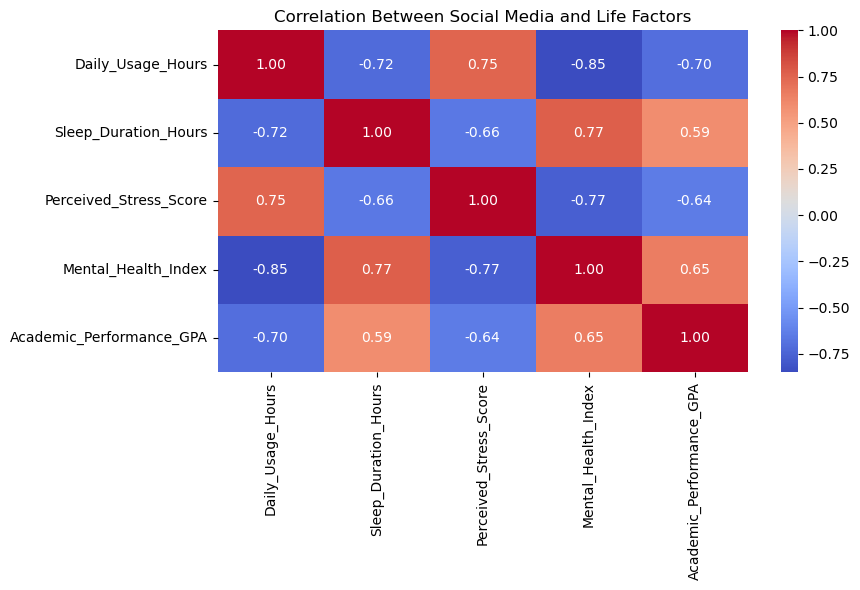

In [14]:

columns = [
    "Daily_Usage_Hours",
    "Sleep_Duration_Hours",
    "Perceived_Stress_Score",
    "Mental_Health_Index",
    "Academic_Performance_GPA"
]

columns = [col for col in columns if col in df.columns]

correlation = df[columns].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Social Media and Life Factors")
plt.tight_layout()
plt.show()
